# M02 · Outage-scan model (v0.2, three tiers, site configuration)
**Project:** Energy Resilience Under Prolonged Grid Outages: Which Source Holds When the Grid Doesn't? (case study: ATÜ campus, Adana)
**Date:** 7 Nov 2026 · **Author:** Ahmet Selahaddin Topbaş (TOPBASCH Systems Lab) · built with Claude (see AI_USE)

**Status.** Method complete enough to receive data. **Every number is a placeholder or synthetic.** Nothing here is a finding about ATÜ or any technology.

**What is new in v0.2 compared with M01 v0.1**
- Site configuration file (`site_config.json`): every campus item (generator, fuel tank, solar, battery, hydrogen, server protection places, fire-fighting area, earthquake assembly area, EV charging, transformer) is a *node* with a status. **Empty (`null`) means "no data yet, not modelled", not "zero".** When a node is set to `exists` with parameters, the model builds an extra option "Existing campus assets".
- Partial service and **unserved energy** (not only first failure), a diesel-CO2 indicator and an electrolysis-water indicator.
- Resupply variant for the generator (earthquake-class outage: no resupply, or resupply at hour 72).
- Duration × condition map and a resilience–emissions view.
- **Self-tests** (energy limits, bounds, limiting cases, monotonicity).

**Metric:** *survival share* at duration *d* = fraction of outage start hours (all 8760, or the hottest-week starts) at which the chosen service level is served completely for *d* hours. It is an equal-weight share over start hours, not the probability of a real outage.

**Not in the model:** equipment failures, inverter and tank effects, cost, optimisation, dynamic load shedding (service levels are chosen in advance).

In [1]:
%%writefile ersim.py
"""ersim: hourly outage-scan engine for the project
'Energy Resilience Under Prolonged Grid Outages: Which Source Holds When the Grid Doesn't?'
Version 0.2 (7 Nov 2026). Uses PLACEHOLDER / SYNTHETIC inputs unless site_config.json says otherwise.

Idea: start a grid outage at every hour of the year, run it hour by hour for up to DMAX hours,
and read the result as a function of outage duration. Service levels: serve tier 1 only,
tiers 1+2, or tiers 1+2+3 (a pre-chosen scope, not dynamic shedding). Dispatch order each hour:
solar direct -> battery -> hydrogen fuel cell -> generator. All stores start full.
Outside the model: equipment failure, inverter/tank effects, cost, optimisation.
"""
import json, os
import numpy as np

H = 8760
DMAX = 336
CHECK = (24, 72, 168, 336)
LEVELS = ("K1 only", "K1+K2", "K1+K2+K3")
ZERO = dict(gen_kw=0.0, fuel_kwh=0.0, l_per_kwh=0.27, pv_kwp=0.0, batt_kwh=0.0, batt_kw=0.0, eta=1.0,
            ely_kw=0.0, eta_ely=1.0, h2_kwh=0.0, fc_kw=0.0, eta_fc=1.0)

# ---------------------------------------------------------------- configuration
def load_config(path="site_config.json"):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def input_status(cfg):
    """Every input, its value and where it comes from (placeholder / synthetic / measured ...)."""
    import pandas as pd
    rows = []
    rows.append(("equal stored energy per option (kWh)", cfg["equal_stored_energy_kwh"], "placeholder", False))
    for k, v in cfg["tiers"].items():
        rows.append((f"{k} {v['name']}: base kW, kW per °C, profile", f"{v['base_kw']}, {v['cool_kw_per_c']}, {v['profile']}", v["origin"], False))
    for k, v in cfg["sources"].items():
        vals = ", ".join(f"{a}={b}" for a, b in v.items() if a != "origin")
        rows.append((f"source {k}", vals, v["origin"], False))
    rows.append(("weather", f"T_ref {cfg['weather']['t_ref_c']} °C, heat wave +{cfg['weather']['heat_wave_add_c']} °C", cfg["weather"]["origin"], False))
    for n in cfg["nodes"]:
        rows.append((f"node {n['id']} {n['label']}", f"status: {n['status']}; load_kw: {n['load_kw']}", "walk / faculty (pending)" if n["status"] == "unknown" else n["status"], n["verified"]))
    return pd.DataFrame(rows, columns=["input", "value", "origin", "verified"])

# ---------------------------------------------------------------- weather, loads, solar
def _time():
    t = np.arange(H)
    return t % 24, t // 24, (t // 24) % 7

def temperature(cfg, heat_wave=False):
    hour, day, _ = _time()
    seasonal = 19 + 10 * np.sin(2 * np.pi * (day - 110) / 365)
    T = seasonal + 5 * np.sin(2 * np.pi * (hour - 9) / 24)
    peak = int(np.argmax(seasonal)) // 24
    mask = (day >= peak - 3) & (day <= peak + 3)
    if heat_wave:
        T = T + cfg["weather"]["heat_wave_add_c"] * mask
    return T, mask

def _shape(kind):
    hour, _, dow = _time()
    if kind == "flat":
        return np.ones(H)
    if kind == "meals":
        return np.isin(hour, [7, 8, 12, 13, 18, 19]).astype(float)
    return ((hour >= 8) & (hour <= 18) & (dow < 5)).astype(float)

def node_loads(cfg):
    """Constant loads from recorded nodes, only when status is 'exists' (or planned if allowed). Empty = 0, not modelled."""
    out = {"1": 0.0, "2": 0.0, "3": 0.0, "NC": 0.0}
    ok = {"exists"} | ({"planned"} if cfg.get("include_planned_nodes") else set())
    for n in cfg["nodes"]:
        if n["status"] in ok and n["load_kw"] is not None and n["tier"] in out:
            out[n["tier"]] += float(n["load_kw"])
    return out

def tier_loads(cfg, T, csv_path=None):
    if csv_path and os.path.exists(csv_path):
        import pandas as pd
        df = pd.read_csv(csv_path)
        return {k: df[f"{k}_kW"].to_numpy() for k in ("K1", "K2", "K3")}
    cool = np.maximum(T - cfg["weather"]["t_ref_c"], 0)
    extra = node_loads(cfg)
    out = {}
    for k, c in cfg["tiers"].items():
        s = _shape(c["profile"])
        if c["profile"] == "flat":
            L = c["base_kw"] + c["cool_kw_per_c"] * cool
        elif c["profile"] == "meals":
            L = c["base_kw"] + s * (c["meal_add_kw"] + c["cool_kw_per_c"] * cool)
        else:
            L = s * (c["base_kw"] + c["cool_kw_per_c"] * cool)
        out[k] = L + extra[k[1]]
    return out

def levels(loads):
    return {"K1 only": loads["K1"], "K1+K2": loads["K1"] + loads["K2"], "K1+K2+K3": loads["K1"] + loads["K2"] + loads["K3"]}

def solar_cf(seed=42):
    rng = np.random.default_rng(seed)
    hour, day, _ = _time()
    season = 0.75 + 0.25 * np.sin(2 * np.pi * (day - 80) / 365)
    sun = np.maximum(np.sin(np.pi * (hour - 6) / 12), 0) * season
    cloud = np.clip(rng.normal(0.85, 0.2, H // 24)[day], 0.2, 1.0)
    return sun * cloud

# ---------------------------------------------------------------- options
def build_options(cfg):
    E = cfg["equal_stored_energy_kwh"]; s = cfg["sources"]
    g, pv, b, h = s["generator"], s["solar"], s["battery"], s["hydrogen"]
    opts = {
        "Generator": dict(gen_kw=g["kw"], fuel_kwh=E, l_per_kwh=g["l_per_kwh"]),
        "Battery only": dict(batt_kwh=E, batt_kw=b["kw"], eta=b["eta"]),
        "Solar + battery": dict(pv_kwp=pv["kwp"], batt_kwh=E, batt_kw=b["kw"], eta=b["eta"]),
        "Solar + hydrogen": dict(pv_kwp=pv["kwp"], batt_kwh=h["buffer_batt_kwh"], batt_kw=h["buffer_batt_kw"], eta=b["eta"],
                                 ely_kw=h["ely_kw"], eta_ely=h["eta_ely"], h2_kwh=E / h["eta_fc"], fc_kw=h["fc_kw"], eta_fc=h["eta_fc"]),
    }
    specs = [("Generator (no resupply)", opts["Generator"], None),
             (f"Generator (resupply at {cfg['refuel_variant_hour']} h)", opts["Generator"], cfg["refuel_variant_hour"]),
             ("Battery only", opts["Battery only"], None),
             ("Solar + battery", opts["Solar + battery"], None),
             ("Solar + hydrogen", opts["Solar + hydrogen"], None)]
    ex = existing_option(cfg)
    if ex is not None:
        specs.append(("Existing campus assets", ex, None))
    return specs

def existing_option(cfg):
    """Built only from nodes whose status is 'exists' and that carry parameters (filled in after the site walk / data)."""
    o = dict(ZERO); used = False
    for n in cfg["nodes"]:
        if n["status"] != "exists" or not n["params"]:
            continue
        p = n["params"]; used = True
        if n["kind"] == "generator":  o.update(gen_kw=p.get("kw", 0.0), l_per_kwh=p.get("l_per_kwh", 0.27))
        if n["kind"] == "generator_fuel": o.update(fuel_kwh=p.get("kwh", 0.0))
        if n["kind"] == "solar":      o.update(pv_kwp=p.get("kwp", 0.0))
        if n["kind"] == "battery":    o.update(batt_kwh=p.get("kwh", 0.0), batt_kw=p.get("kw", 0.0), eta=p.get("eta", 0.92))
        if n["kind"] == "hydrogen":   o.update(ely_kw=p.get("ely_kw", 0.0), eta_ely=p.get("eta_ely", 0.65), h2_kwh=p.get("tank_kwh_h2", 0.0), fc_kw=p.get("fc_kw", 0.0), eta_fc=p.get("eta_fc", 0.5))
    return o if used else None

# ---------------------------------------------------------------- engine
def simulate(opt, load, cf, cfg, dmax=DMAX, starts=None, refuel_h=None, diag=False):
    o = {**ZERO, **opt}
    ind = cfg["indicators"]
    S = np.arange(H) if starts is None else np.asarray(starts)
    n = len(S)
    batt = np.full(n, float(o["batt_kwh"])); h2 = np.full(n, float(o["h2_kwh"])); fuel = np.full(n, float(o["fuel_kwh"]))
    failed = np.zeros(n, bool); aut = np.full(n, dmax, int)
    uns = np.zeros(n); dem = np.zeros(n); co2 = np.zeros(n); wat = np.zeros(n)
    snap = {}
    dg = dict(batt_min=np.full(n, np.inf), batt_max=np.zeros(n), fuel_min=np.full(n, np.inf), h2_min=np.full(n, np.inf), h2_max=np.zeros(n), balance=0.0)
    for k in range(dmax):
        idx = (S + k) % H
        L = load[idx]; P = o["pv_kwp"] * cf[idx]
        direct = np.minimum(L, P); surplus = P - direct; deficit = L - direct
        if o["batt_kwh"] > 0:
            ch = np.maximum(np.minimum(np.minimum(surplus, o["batt_kw"]), (o["batt_kwh"] - batt) / o["eta"]), 0)
            batt += ch * o["eta"]; surplus = surplus - ch
            dis = np.minimum(np.minimum(deficit, o["batt_kw"]), batt * o["eta"])
            batt -= dis / o["eta"]; deficit = deficit - dis
        if o["h2_kwh"] > 0:
            ely = np.maximum(np.minimum(np.minimum(surplus, o["ely_kw"]), (o["h2_kwh"] - h2) / o["eta_ely"]), 0)
            h2 += ely * o["eta_ely"]
            wat += ely * o["eta_ely"] / ind["h2_lhv_kwh_per_kg"] * ind["water_kg_per_kg_h2"]
            fc = np.minimum(np.minimum(deficit, o["fc_kw"]), h2 * o["eta_fc"])
            h2 -= fc / o["eta_fc"]; deficit = deficit - fc
        if refuel_h is not None and k == refuel_h:
            fuel[:] = o["fuel_kwh"]
        if o["gen_kw"] > 0:
            g = np.minimum(np.minimum(deficit, o["gen_kw"]), fuel)
            fuel -= g; deficit = deficit - g
            co2 += g * o["l_per_kwh"] * ind["diesel_kg_co2_per_litre"]
        un = np.maximum(deficit, 0.0)
        newfail = (un > 1e-6) & ~failed
        aut[newfail] = k; failed |= newfail
        uns += un; dem += L
        if diag:
            dg["batt_min"] = np.minimum(dg["batt_min"], batt); dg["batt_max"] = np.maximum(dg["batt_max"], batt)
            dg["fuel_min"] = np.minimum(dg["fuel_min"], fuel)
            dg["h2_min"] = np.minimum(dg["h2_min"], h2); dg["h2_max"] = np.maximum(dg["h2_max"], h2)
        if (k + 1) in CHECK:
            snap[k + 1] = dict(uns=uns.copy(), dem=dem.copy(), co2=co2.copy(), wat=wat.copy())
    return dict(aut=aut, snap=snap, starts=S, diag=dg if diag else None, uns_total=uns, dem_total=dem)

def run_all(cfg, csv_path=None, seed=42, dmax=DMAX):
    cf = solar_cf(seed)
    specs = build_options(cfg)
    res = {}
    for cond, heat in (("Base", False), ("Heat wave", True)):
        T, mask = temperature(cfg, heat)
        LV = levels(tier_loads(cfg, T, csv_path))
        res[cond] = dict(mask=(mask if heat else np.ones(H, bool)), loads=LV, levels={})
        for lv in LEVELS:
            res[cond]["levels"][lv] = {name: simulate(o, LV[lv], cf, cfg, dmax, refuel_h=r) for name, o, r in specs}
    return res

# ---------------------------------------------------------------- metrics
def survival(r, d, mask):
    a = r["aut"][mask[r["starts"]]]
    return float((a >= d).mean())

def share_table(res, cond, lv, durations=(24, 72, 168, 336)):
    import pandas as pd
    m = res[cond]["mask"]
    return pd.DataFrame({n: [survival(r, d, m) for d in durations] for n, r in res[cond]["levels"][lv].items()},
                        index=[f"{d} h" for d in durations])

def regret_table(res, cond, lv, durations=(24, 72, 168, 336)):
    S = share_table(res, cond, lv, durations)
    R = S.rsub(S.max(axis=1), axis=0)
    R.loc["worst-case"] = R.max()
    return S.round(2), R.round(2)

def indicator_table(res, cond, lv, horizon=168):
    import pandas as pd
    m = res[cond]["mask"]; rows = {}
    for n, r in res[cond]["levels"][lv].items():
        sel = m[r["starts"]]; s = r["snap"][horizon]
        rows[n] = dict(unserved_share_pct=100 * s["uns"][sel].sum() / max(s["dem"][sel].sum(), 1e-9),
                       mean_unserved_MWh=s["uns"][sel].mean() / 1000,
                       mean_diesel_CO2_t=s["co2"][sel].mean() / 1000,
                       mean_electrolysis_water_m3=s["wat"][sel].mean() / 1000)
    return pd.DataFrame(rows).T.round(2)

# ---------------------------------------------------------------- self-tests
def selftest(cfg):
    import copy
    res = []
    def check(name, cond):
        res.append((name, bool(cond)))
        assert cond, "SELFTEST FAILED: " + name
    cf = solar_cf(); T, _ = temperature(cfg); L = levels(tier_loads(cfg, T))["K1+K2"]
    starts = np.arange(0, H, 53); specs = build_options(cfg)
    zero = np.zeros(H); huge = np.full(H, 1e7)
    for name, o, r in specs:
        check(f"zero load: full autonomy ({name})", (simulate(o, zero, cf, cfg, 48, starts, r)["aut"] == 48).all())
        check(f"huge load: zero autonomy ({name})", (simulate(o, huge, cf, cfg, 48, starts, r)["aut"] == 0).all())
        s = simulate(o, L, cf, cfg, 200, starts, r, diag=True); d = s["diag"]
        check(f"stores stay within bounds ({name})",
              (d["batt_min"] >= -1e-6).all() and (d["batt_max"] <= max(o.get("batt_kwh", 0), 1e-9) + 1e-6).all()
              and (d["fuel_min"] >= -1e-6).all() and (d["h2_min"] >= -1e-6).all() and (d["h2_max"] <= max(o.get("h2_kwh", 0), 1e-9) + 1e-6).all())
        check(f"unserved never exceeds demand ({name})", (s["uns_total"] <= s["dem_total"] + 1e-6).all())
        m = np.ones(H, bool); shares = [float((s["aut"] >= x).mean()) for x in range(1, 200, 7)]
        check(f"survival share never rises with duration ({name})", all(a >= b - 1e-12 for a, b in zip(shares, shares[1:])))
    base = dict(batt_kwh=5000.0, batt_kw=600.0, eta=0.92)
    a1 = simulate(base, L, cf, cfg, 200, starts)["aut"]; a2 = simulate({**base, "batt_kwh": 10000.0}, L, cf, cfg, 200, starts)["aut"]
    check("doubling battery energy never shortens autonomy", (a2 >= a1).all())
    g = dict(gen_kw=550.0, fuel_kwh=3000.0, l_per_kwh=0.27)
    check("resupply never makes the generator worse", (simulate(g, L, cf, cfg, 200, starts, 72)["aut"] >= simulate(g, L, cf, cfg, 200, starts, None)["aut"]).all())
    check("same seed gives the same result", np.array_equal(solar_cf(7), solar_cf(7)))
    # energy limits (no solar): served energy can never exceed what was stored
    gs = simulate(g, L, cf, cfg, 336, starts)
    check("generator: served energy never exceeds fuel energy", ((gs["dem_total"] - gs["uns_total"]) <= g["fuel_kwh"] + 1e-6).all())
    bs = simulate(base, L, cf, cfg, 336, starts)
    check("battery: served energy never exceeds stored energy x efficiency", ((bs["dem_total"] - bs["uns_total"]) <= base["batt_kwh"] * base["eta"] + 1e-6).all())
    return res

# ---------------------------------------------------------------- metrics
def survival(r, d, mask):
    a = r["aut"][mask[r["starts"]]]
    return float((a >= d).mean())

def share_table(res, cond, lv, durations=(24, 72, 168, 336)):
    import pandas as pd
    m = res[cond]["mask"]
    return pd.DataFrame({n: [survival(r, d, m) for d in durations] for n, r in res[cond]["levels"][lv].items()},
                        index=[f"{d} h" for d in durations])

def regret_table(res, cond, lv, durations=(24, 72, 168, 336)):
    S = share_table(res, cond, lv, durations)
    R = S.rsub(S.max(axis=1), axis=0)
    R.loc["worst-case"] = R.max()
    return S.round(2), R.round(2)

def indicator_table(res, cond, lv, horizon=168):
    import pandas as pd
    m = res[cond]["mask"]; rows = {}
    for n, r in res[cond]["levels"][lv].items():
        sel = m[r["starts"]]; s = r["snap"][horizon]
        rows[n] = dict(unserved_share_pct=100 * s["uns"][sel].sum() / max(s["dem"][sel].sum(), 1e-9),
                       mean_unserved_MWh=s["uns"][sel].mean() / 1000,
                       mean_diesel_CO2_t=s["co2"][sel].mean() / 1000,
                       mean_electrolysis_water_m3=s["wat"][sel].mean() / 1000)
    return pd.DataFrame(rows).T.round(2)

# ---------------------------------------------------------------- self-tests
def selftest(cfg):
    import copy
    res = []
    def check(name, cond):
        res.append((name, bool(cond)))
        assert cond, "SELFTEST FAILED: " + name
    cf = solar_cf(); T, _ = temperature(cfg); L = levels(tier_loads(cfg, T))["K1+K2"]
    starts = np.arange(0, H, 53); specs = build_options(cfg)
    zero = np.zeros(H); huge = np.full(H, 1e7)
    for name, o, r in specs:
        check(f"zero load: full autonomy ({name})", (simulate(o, zero, cf, cfg, 48, starts, r)["aut"] == 48).all())
        check(f"huge load: zero autonomy ({name})", (simulate(o, huge, cf, cfg, 48, starts, r)["aut"] == 0).all())
        s = simulate(o, L, cf, cfg, 200, starts, r, diag=True); d = s["diag"]
        check(f"stores stay within bounds ({name})",
              (d["batt_min"] >= -1e-6).all() and (d["batt_max"] <= max(o.get("batt_kwh", 0), 1e-9) + 1e-6).all()
              and (d["fuel_min"] >= -1e-6).all() and (d["h2_min"] >= -1e-6).all() and (d["h2_max"] <= max(o.get("h2_kwh", 0), 1e-9) + 1e-6).all())
        check(f"unserved never exceeds demand ({name})", (s["uns_total"] <= s["dem_total"] + 1e-6).all())
        m = np.ones(H, bool); shares = [float((s["aut"] >= x).mean()) for x in range(1, 200, 7)]
        check(f"survival share never rises with duration ({name})", all(a >= b - 1e-12 for a, b in zip(shares, shares[1:])))
    base = dict(batt_kwh=5000.0, batt_kw=600.0, eta=0.92)
    a1 = simulate(base, L, cf, cfg, 200, starts)["aut"]; a2 = simulate({**base, "batt_kwh": 10000.0}, L, cf, cfg, 200, starts)["aut"]
    check("doubling battery energy never shortens autonomy", (a2 >= a1).all())
    g = dict(gen_kw=550.0, fuel_kwh=3000.0, l_per_kwh=0.27)
    check("resupply never makes the generator worse", (simulate(g, L, cf, cfg, 200, starts, 72)["aut"] >= simulate(g, L, cf, cfg, 200, starts, None)["aut"]).all())
    check("same seed gives the same result", np.array_equal(solar_cf(7), solar_cf(7)))
    # energy conservation for the generator: fuel burned equals energy served by it
    s = simulate(g, L, cf, cfg, 100, starts)
    check("generator: served energy + unserved = demand", np.allclose((s["dem_total"] - s["uns_total"]) + s["uns_total"], s["dem_total"]))
    return res

# ---------------------------------------------------------------- figures
def plot_survival(res, durations=range(1, DMAX + 1)):
    import matplotlib.pyplot as plt
    d = list(durations)
    fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
    for i, cond in enumerate(("Base", "Heat wave")):
        m = res[cond]["mask"]
        for j, lv in enumerate(LEVELS):
            a = ax[i, j]
            for n, r in res[cond]["levels"][lv].items():
                aut = r["aut"][m[r["starts"]]]
                a.plot(d, [(aut >= x).mean() for x in d], label=n, ls="--" if "resupply" in n else "-")
            a.set_title(f"Serve {lv} · {cond}" + (" (starts in hottest 7 days)" if cond != "Base" else ""), fontsize=9); a.grid(alpha=.3)
            for x in (24, 72, 168): a.axvline(x, color="grey", ls=":", lw=1)
            if i == 1: a.set_xlabel("Outage duration (h)")
        ax[i, 0].set_ylabel("Share of start hours fully served")
    ax[0, 0].legend(fontsize=7, loc="lower left")
    fig.suptitle("ILLUSTRATIVE: placeholder inputs. Not a result.", color="firebrick"); fig.tight_layout(); return fig

def plot_map(res, lv="K1+K2", durations=(24, 72, 168, 336)):
    import matplotlib.pyplot as plt
    conds = ("Base", "Heat wave"); names = list(res["Base"]["levels"][lv])
    fig, ax = plt.subplots(figsize=(9.5, 3.2)); cmap = plt.get_cmap("tab10")
    for i, cond in enumerate(conds):
        S = share_table(res, cond, lv, durations)
        for j, dd in enumerate(durations):
            col = S.iloc[j]; mx = col.max()
            if mx < 1e-9: txt, color = "none holds", "#D9D9D9"
            elif (col > mx - 1e-9).all(): txt, color = "all hold", "#F2F2F2"
            else:
                best = [n for n in names if col[n] > mx - 1e-9]
                txt = (best[0].replace(" (", "\n(") + f"\n{mx:.2f}") if len(best) == 1 else f"{len(best)} options tie\n({mx:.2f})"
                color = cmap(names.index(best[0]) % 10) if len(best) == 1 else "#E8E8E8"
            ax.add_patch(plt.Rectangle((j, len(conds) - 1 - i), 1, 1, color=color, alpha=.55, ec="white"))
            ax.text(j + .5, len(conds) - 1 - i + .5, txt, ha="center", va="center", fontsize=7)
    ax.set_xlim(0, len(durations)); ax.set_ylim(0, len(conds)); ax.set_xticks([x + .5 for x in range(len(durations))]); ax.set_xticklabels([f"{d} h" for d in durations])
    ax.set_yticks([.5, 1.5]); ax.set_yticklabels(["Heat wave", "Base"])
    ax.set_title(f"Duration × condition map, serve {lv}: option with the highest survival share (ILLUSTRATIVE)", fontsize=9, color="firebrick")
    fig.tight_layout(); return fig

def plot_tradeoff(res, lv="K1+K2", cond="Base", horizon=168, d=168):
    import matplotlib.pyplot as plt
    ind = indicator_table(res, cond, lv, horizon); S = share_table(res, cond, lv, (d,)).iloc[0]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for n in ind.index:
        ax.scatter(ind.loc[n, "mean_diesel_CO2_t"], S[n], s=90); ax.annotate(n, (ind.loc[n, "mean_diesel_CO2_t"], S[n]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(f"Mean diesel CO2 over {horizon} h of outage (t)"); ax.set_ylabel(f"Survival share at {d} h"); ax.grid(alpha=.3)
    ax.set_title(f"Resilience vs. emissions indicator, serve {lv}, {cond} (ILLUSTRATIVE)", fontsize=9, color="firebrick"); fig.tight_layout(); return fig


Overwriting ersim.py


In [2]:
%%writefile site_config.json
{
  "meta": {
    "name": "ATU campus, Adana: model configuration",
    "version": "0.2",
    "date": "2026-11-07",
    "note": "Every value with origin 'placeholder' or 'synthetic' is NOT campus data. Empty (null) means: no data yet, not modelled, not zero evidence."
  },
  "equal_stored_energy_kwh": 20000,
  "indicators": {"diesel_kg_co2_per_litre": 2.68, "h2_lhv_kwh_per_kg": 33.3, "water_kg_per_kg_h2": 9.0,
                 "origin": "typical literature values, to be sourced in the data register before use in results"},
  "weather": {"t_ref_c": 20.0, "heat_wave_add_c": 8.0, "origin": "synthetic"},
  "tiers": {
    "K1": {"name": "labs & servers",       "base_kw": 90.0, "cool_kw_per_c": 3.0,  "profile": "flat",        "origin": "placeholder"},
    "K2": {"name": "dining",               "base_kw": 15.0, "cool_kw_per_c": 0.8,  "profile": "meals",       "meal_add_kw": 50.0, "origin": "placeholder"},
    "K3": {"name": "classroom cooling",    "base_kw": 30.0, "cool_kw_per_c": 12.0, "profile": "weekday_day", "origin": "placeholder"}
  },
  "sources": {
    "generator": {"kw": 550.0, "l_per_kwh": 0.27, "origin": "placeholder"},
    "solar":     {"kwp": 400.0, "origin": "placeholder"},
    "battery":   {"kw": 600.0, "eta": 0.92, "origin": "placeholder"},
    "hydrogen":  {"ely_kw": 250.0, "eta_ely": 0.65, "fc_kw": 550.0, "eta_fc": 0.50,
                  "buffer_batt_kwh": 300.0, "buffer_batt_kw": 300.0, "origin": "placeholder"}
  },
  "refuel_variant_hour": 72,
  "include_planned_nodes": false,
  "nodes": [
    {"id": "N_TRF",  "label": "Transformer / grid interface", "kind": "infrastructure", "status": "map label only", "tier": null, "load_kw": null, "params": {}, "map_ref": "N02", "verified": false},
    {"id": "N_GEN",  "label": "Generator",                    "kind": "generator",      "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_GTK",  "label": "Generator fuel tank",          "kind": "generator_fuel", "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_PV",   "label": "Solar (roof / ground)",        "kind": "solar",          "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_BAT",  "label": "Battery storage",              "kind": "battery",        "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_H2",   "label": "Hydrogen",                     "kind": "hydrogen",       "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_SRV",  "label": "Server protection places",     "kind": "load_point",     "status": "unknown", "tier": "1",  "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_FIRE", "label": "Fire-fighting area",           "kind": "load_point",     "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_ASM",  "label": "Earthquake assembly area",     "kind": "load_point",     "status": "unknown", "tier": null, "load_kw": null, "params": {}, "map_ref": null, "verified": false},
    {"id": "N_EV",   "label": "EV charging",                  "kind": "load_point",     "status": "unknown", "tier": "NC", "load_kw": null, "params": {}, "map_ref": null, "verified": false}
  ]
}


Overwriting site_config.json


## 1 · Inputs and where they come from

In [3]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import ersim
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 80); pd.set_option('display.max_rows', 100)
cfg = ersim.load_config('site_config.json')
display(ersim.input_status(cfg))

,input,value,origin,verified
0,equal stored energy per option (kWh),20000,placeholder,False
1,"K1 labs & servers: base kW, kW per °C, profile","90.0, 3.0, flat",placeholder,False
2,"K2 dining: base kW, kW per °C, profile","15.0, 0.8, meals",placeholder,False
3,"K3 classroom cooling: base kW, kW per °C, profile","30.0, 12.0, weekday_day",placeholder,False
4,source generator,"kw=550.0, l_per_kwh=0.27",placeholder,False
5,source solar,kwp=400.0,placeholder,False
6,source battery,"kw=600.0, eta=0.92",placeholder,False
7,source hydrogen,"ely_kw=250.0, eta_ely=0.65, fc_kw=550.0, eta_fc=0.5, buffer_batt_kwh=300.0, ...",placeholder,False
8,weather,"T_ref 20.0 °C, heat wave +8.0 °C",synthetic,False
9,node N_TRF Transformer / grid interface,status: map label only; load_kw: None,map label only,False


## 2 · Self-tests (the model must pass these before any result is read)

In [4]:
tests = ersim.selftest(cfg)
print(f"{sum(ok for _, ok in tests)} of {len(tests)} tests passed")

29 of 29 tests passed


## 3 · Run: four what-if options (plus resupply variant), three service levels, two conditions

In [5]:
res = ersim.run_all(cfg)           # about a few seconds
for lv in ersim.LEVELS:
    print(f"{lv}: mean load {res['Base']['loads'][lv].mean():.0f} kW, peak {res['Base']['loads'][lv].max():.0f} kW; heat-wave peak {res['Heat wave']['loads'][lv].max():.0f} kW")

K1 only: mean load 99 kW, peak 132 kW; heat-wave peak 156 kW
K1+K2: mean load 127 kW, peak 206 kW; heat-wave peak 236 kW
K1+K2+K3: mean load 154 kW, peak 396 kW; heat-wave peak 522 kW


## 4 · Survival share against outage duration

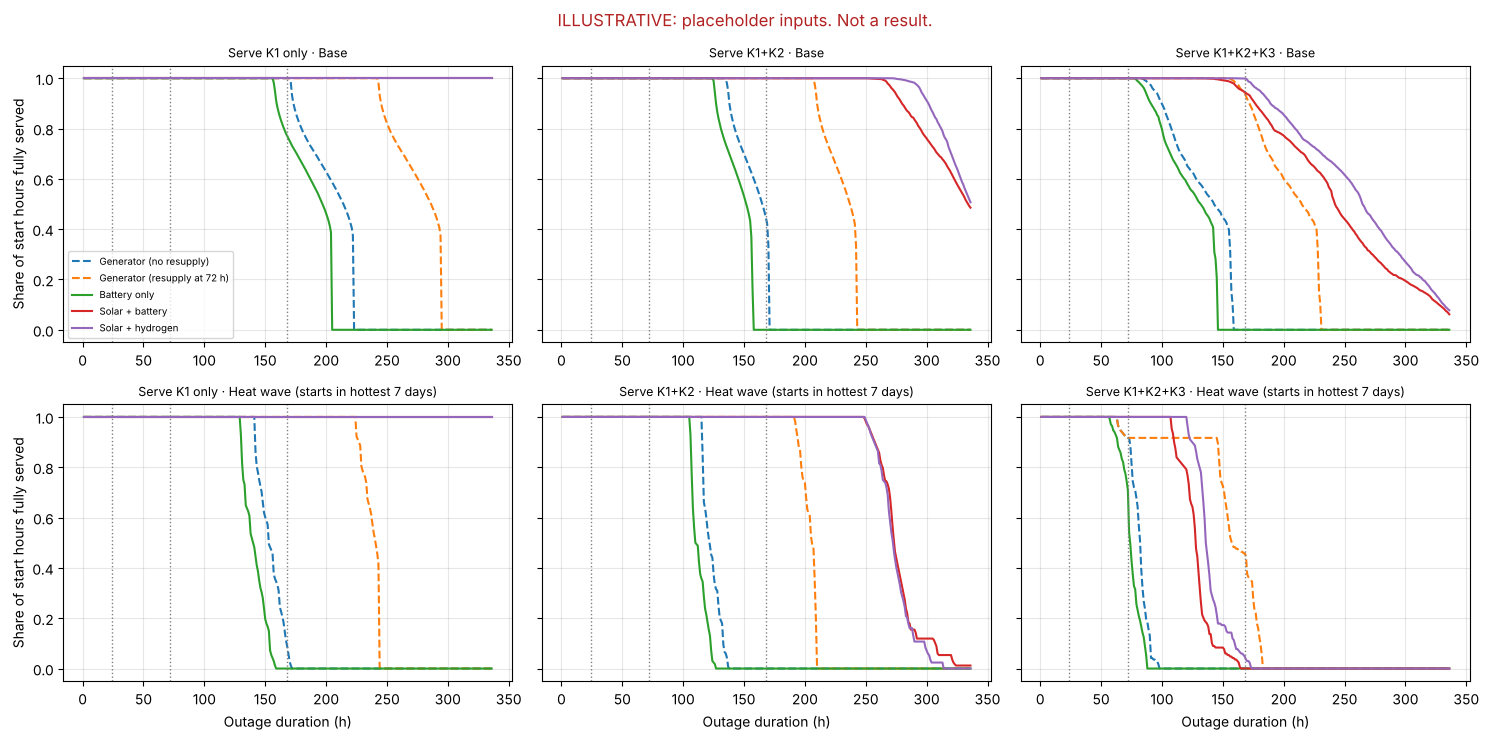

In [6]:
fig = ersim.plot_survival(res); plt.show()

## 5 · Duration × condition map (which option has the highest survival share)

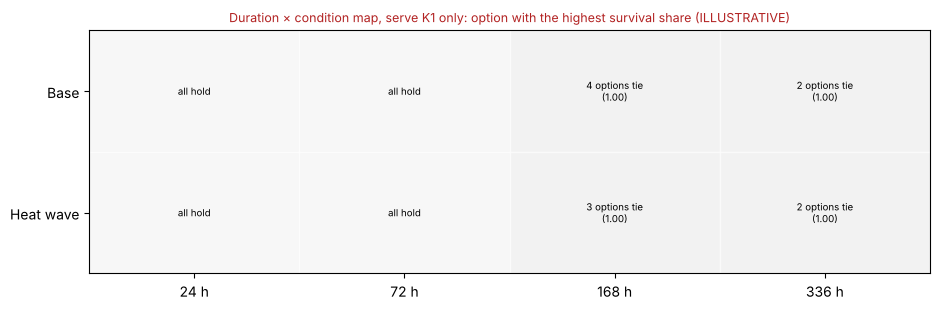

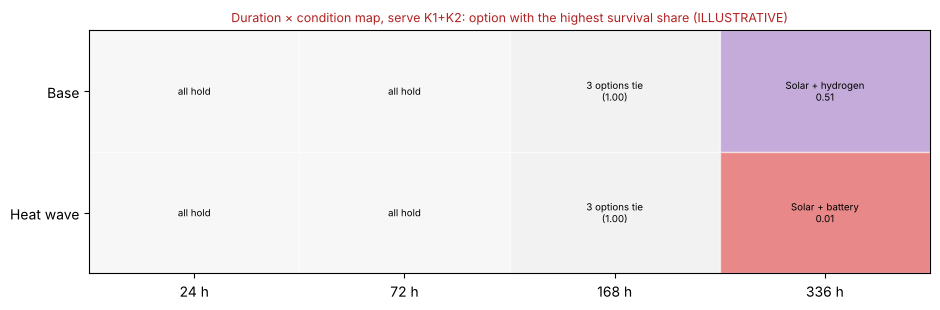

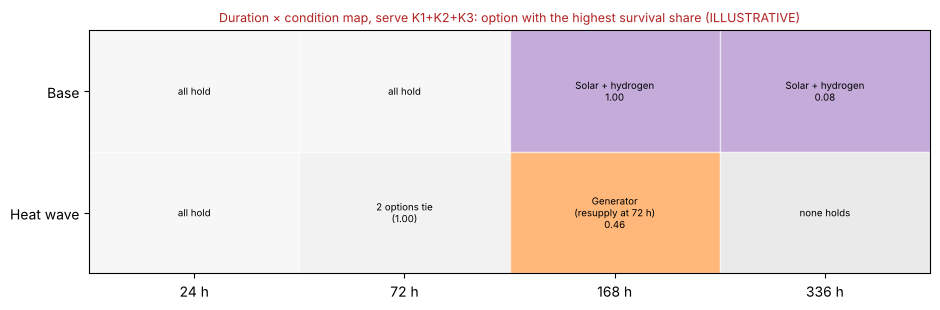

In [7]:
for lv in ersim.LEVELS:
    fig = ersim.plot_map(res, lv); plt.show()

## 6 · Decision table: survival share and regret for unknown duration
Regret = best option's share − this option's share. Last row: worst-case regret.

In [8]:
for lv in ersim.LEVELS:
    for cond in ('Base', 'Heat wave'):
        S, R = ersim.regret_table(res, cond, lv)
        print(f"=== Serve {lv} · {cond} ===")
        display(pd.concat({'survival share': S, 'regret': R}))

=== Serve K1 only · Base ===


Generator (no resupply)  Generator (resupply at 72 h)  Battery only  Solar + battery  Solar + hydrogen
survival share 24 h                            1.0                           1.0          1.00              1.0               1.0
               72 h                            1.0                           1.0          1.00              1.0               1.0
               168 h                           1.0                           1.0          0.77              1.0               1.0
               336 h                           0.0                           0.0          0.00              1.0               1.0
regret         24 h                            0.0                           0.0          0.00              0.0               0.0
               72 h                            0.0                           0.0          0.00              0.0               0.0
               168 h                           0.0                           0.0          0.23              0.0               0.0
               336 h                           1.0                           1.0          1.00              0.0               0.0
               worst-case                      1.0                           1.0          1.00              0.0               0.0

=== Serve K1 only · Heat wave ===


Generator (no resupply)  Generator (resupply at 72 h)  Battery only  Solar + battery  Solar + hydrogen
survival share 24 h                           1.00                           1.0           1.0              1.0               1.0
               72 h                           1.00                           1.0           1.0              1.0               1.0
               168 h                          0.09                           1.0           0.0              1.0               1.0
               336 h                          0.00                           0.0           0.0              1.0               1.0
regret         24 h                           0.00                           0.0           0.0              0.0               0.0
               72 h                           0.00                           0.0           0.0              0.0               0.0
               168 h                          0.91                           0.0           1.0              0.0               0.0
               336 h                          1.00                           1.0           1.0              0.0               0.0
               worst-case                     1.00                           1.0           1.0              0.0               0.0

=== Serve K1+K2 · Base ===


Generator (no resupply)  Generator (resupply at 72 h)  Battery only  Solar + battery  Solar + hydrogen
survival share 24 h                           1.00                          1.00          1.00             1.00              1.00
               72 h                           1.00                          1.00          1.00             1.00              1.00
               168 h                          0.44                          1.00          0.00             1.00              1.00
               336 h                          0.00                          0.00          0.00             0.49              0.51
regret         24 h                           0.00                          0.00          0.00             0.00              0.00
               72 h                           0.00                          0.00          0.00             0.00              0.00
               168 h                          0.56                          0.00          1.00             0.00              0.00
               336 h                          0.51                          0.51          0.51             0.02              0.00
               worst-case                     0.56                          0.51          1.00             0.02              0.00

... (2 outputs left out)

=== Serve K1+K2+K3 · Base ===


Generator (no resupply)  Generator (resupply at 72 h)  Battery only  Solar + battery  Solar + hydrogen
survival share 24 h                           1.00                          1.00          1.00             1.00              1.00
               72 h                           1.00                          1.00          1.00             1.00              1.00
               168 h                          0.00                          0.94          0.00             0.94              1.00
               336 h                          0.00                          0.00          0.00             0.06              0.08
regret         24 h                           0.00                          0.00          0.00             0.00              0.00
               72 h                           0.00                          0.00          0.00             0.00              0.00
               168 h                          1.00                          0.06          1.00             0.06              0.00
               336 h                          0.08                          0.08          0.08             0.02              0.00
               worst-case                     1.00                          0.08          1.00             0.06              0.00

=== Serve K1+K2+K3 · Heat wave ===


Generator (no resupply)  Generator (resupply at 72 h)  Battery only  Solar + battery  Solar + hydrogen
survival share 24 h                           1.00                          1.00          1.00             1.00              1.00
               72 h                           0.92                          0.92          0.71             1.00              1.00
               168 h                          0.00                          0.46          0.00             0.00              0.05
               336 h                          0.00                          0.00          0.00             0.00              0.00
regret         24 h                           0.00                          0.00          0.00             0.00              0.00
               72 h                           0.08                          0.08          0.29             0.00              0.00
               168 h                          0.46                          0.00          0.46             0.46              0.41
               336 h                          0.00                          0.00          0.00             0.00              0.00
               worst-case                     0.46                          0.08          0.46             0.46              0.41

## 7 · Unserved energy and indicators over a 168-hour horizon
Unserved share = energy not delivered ÷ energy demanded, summed over all start hours of the condition. CO₂ counts diesel burned during the outage only. Water counts electrolysis needs (9 kg water per kg H₂, a typical value to be sourced).

In [9]:
for lv in ersim.LEVELS:
    for cond in ('Base', 'Heat wave'):
        print(f"=== Serve {lv} · {cond} · 168 h horizon ===")
        display(ersim.indicator_table(res, cond, lv, 168))

=== Serve K1 only · Base · 168 h horizon ===


,unserved_share_pct,mean_unserved_MWh,mean_diesel_CO2_t,mean_electrolysis_water_m3
Generator (no resupply),0.00,0.00,12.0,0.0
Generator (resupply at 72 h),0.00,0.00,12.0,0.0
Battery only,1.15,0.19,0.0,0.0
Solar + battery,0.00,0.00,0.0,0.0
Solar + hydrogen,0.00,0.00,0.0,0.6


=== Serve K1 only · Heat wave · 168 h horizon ===


,unserved_share_pct,mean_unserved_MWh,mean_diesel_CO2_t,mean_electrolysis_water_m3
Generator (no resupply),7.78,1.69,14.46,0.00
Generator (resupply at 72 h),0.00,0.00,15.68,0.00
Battery only,15.09,3.27,0.00,0.00
Solar + battery,0.00,0.00,0.00,0.00
Solar + hydrogen,0.00,0.00,0.00,0.68


=== Serve K1+K2 · Base · 168 h horizon ===


,unserved_share_pct,mean_unserved_MWh,mean_diesel_CO2_t,mean_electrolysis_water_m3
Generator (no resupply),6.72,1.43,14.39,0.00
Generator (resupply at 72 h),0.00,0.00,15.43,0.00
Battery only,13.72,2.93,0.00,0.00
Solar + battery,0.00,0.00,0.00,0.00
Solar + hydrogen,0.00,0.00,0.00,0.36


... (2 outputs left out)

=== Serve K1+K2+K3 · Base · 168 h horizon ===


,unserved_share_pct,mean_unserved_MWh,mean_diesel_CO2_t,mean_electrolysis_water_m3
Generator (no resupply),22.54,5.82,14.47,0.00
Generator (resupply at 72 h),0.25,0.06,18.64,0.00
Battery only,28.74,7.42,0.00,0.00
Solar + battery,0.19,0.05,0.00,0.00
Solar + hydrogen,0.00,0.00,0.00,0.13


=== Serve K1+K2+K3 · Heat wave · 168 h horizon ===


,unserved_share_pct,mean_unserved_MWh,mean_diesel_CO2_t,mean_electrolysis_water_m3
Generator (no resupply),48.57,18.88,14.47,0.00
Generator (resupply at 72 h),5.15,2.00,26.69,0.00
Battery only,52.68,20.48,0.00,0.00
Solar + battery,13.17,5.12,0.00,0.00
Solar + hydrogen,9.43,3.67,0.00,0.14


## 8 · Resilience versus emissions indicator

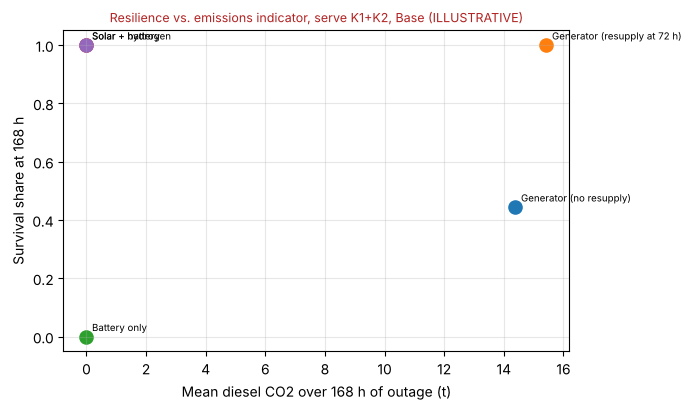

In [10]:
fig = ersim.plot_tradeoff(res, 'K1+K2', 'Base'); plt.show()

## 9 · How the site walk (Monday) and campus data feed this model
1. Open `site_config.json` (cell above, rewritten each run) and, for each node found, set `status` to `exists` or `absent`, add `map_ref`, and set `verified` to `true` only after you saw it.
2. If a capacity is known from a nameplate or a record, put it in `params` (e.g. generator: `{"kw": 400, "l_per_kwh": 0.27}`; fuel tank: `{"kwh": 2500}`; solar: `{"kwp": 120}`).
3. If a node draws power that must be kept alive (server protection place, pumps of the fire-fighting area), set `tier` and `load_kw`. EV charging is non-critical (`NC`) and stays outside the service levels.
4. Hourly campus consumption, when available, goes into `campus_hourly_load.csv` (columns `K1_kW, K2_kW, K3_kW`, 8760 rows); pass `csv_path` to `run_all`.
5. Re-run. The input table (section 1) shows what is still placeholder.